# Notebook 2 — Graph Construction and Community Detection
**Goal:** Compare unweighted, shared-tag-count, and Jaccard-weighted book networks using the same books and candidate edges.

This notebook reads outputs from Notebook 1. It filters generic/high-frequency tags, selects a deterministic subset for computational feasibility, constructs three graphs, runs Louvain, evaluates modularity and tag coherence, and saves tables and figures.

**Research caution:** The subset and filtering rules affect results. Report them clearly and do not assume one method is best before evaluating the actual results.

## 1. Imports and paths

In [1]:
from pathlib import Path
from itertools import combinations
from collections import Counter
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

RANDOM_STATE = 42
cwd = Path.cwd().resolve()
if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
elif (cwd / "notebooks").is_dir():
    PROJECT_ROOT = cwd
else:
    raise FileNotFoundError(f"Could not identify project root from {cwd}")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
for folder in (TABLE_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_DIR)
print("NetworkX:", nx.__version__)

Project root: C:\Users\Nethmi\Desktop\goodbooks-graph-research
Processed data: C:\Users\Nethmi\Desktop\goodbooks-graph-research\data\processed
NetworkX: 3.6.1


## 2. Load and validate processed data

In [2]:
needed = ["graph_tag_rows.csv", "books_clean.csv"]
missing = [f for f in needed if not (PROCESSED_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run Notebook 1 first.")

tag_rows = pd.read_csv(PROCESSED_DIR / "graph_tag_rows.csv",
                       usecols=["goodreads_book_id", "tag_id", "count", "tag_name"])
books = pd.read_csv(PROCESSED_DIR / "books_clean.csv",
                    usecols=["book_id", "title", "authors", "average_rating"])
tag_rows = tag_rows.dropna(subset=["goodreads_book_id", "tag_id", "tag_name"]).copy()
tag_rows["goodreads_book_id"] = tag_rows["goodreads_book_id"].astype("int64")
tag_rows["tag_id"] = tag_rows["tag_id"].astype("int64")
tag_rows["tag_name"] = tag_rows["tag_name"].astype(str).str.strip().str.lower()
tag_rows = tag_rows.drop_duplicates(["goodreads_book_id", "tag_id"])
print(f"Book-tag rows: {len(tag_rows):,}")
print(f"Books: {tag_rows['goodreads_book_id'].nunique():,}")
print(f"Tags: {tag_rows['tag_id'].nunique():,}")
display(tag_rows.head())

Book-tag rows: 999,904
Books: 10,000
Tags: 34,252


,goodreads_book_id,tag_id,tag_name,count
0,1,30574,to-read,167697
1,1,11305,fantasy,37174
2,1,11557,favorites,34173
3,1,8717,currently-reading,12986
4,1,33114,young-adult,12716


## 3. Inspect tag frequencies

,tag_id,tag_name,books_with_tag
30574,30574,to-read,9983
11557,11557,favorites,9881
22743,22743,owned,9857
5207,5207,books-i-own,9799
8717,8717,currently-reading,9776
18045,18045,library,9415
22753,22753,owned-books,9221
11743,11743,fiction,9097
30521,30521,to-buy,8692
17213,17213,kindle,8316


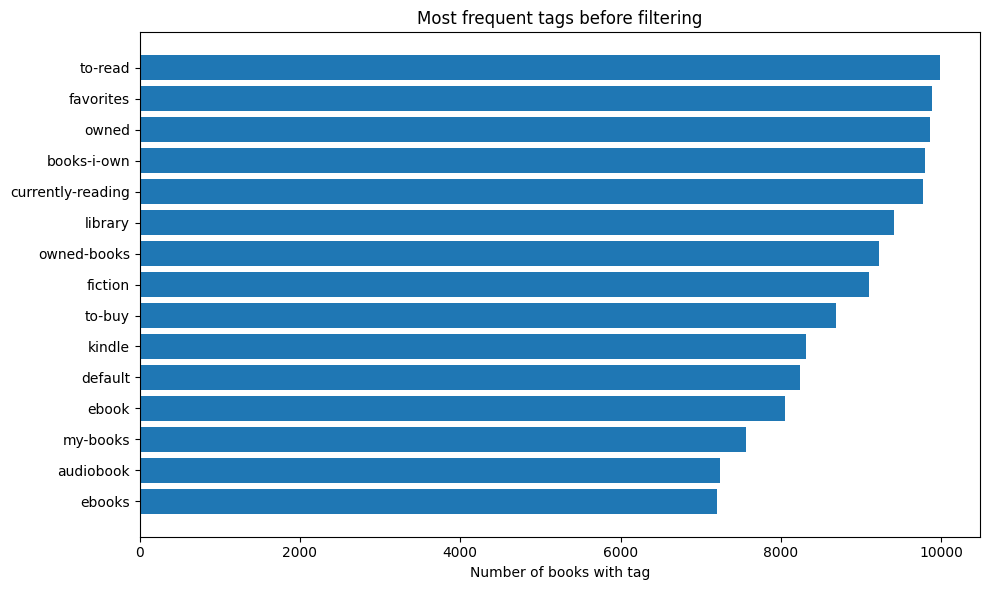

In [3]:
tag_frequency = (tag_rows.groupby(["tag_id", "tag_name"])["goodreads_book_id"]
                 .nunique().rename("books_with_tag").reset_index()
                 .sort_values("books_with_tag", ascending=False))
display(tag_frequency.head(20))
top = tag_frequency.head(15).sort_values("books_with_tag")
plt.figure(figsize=(10, 6))
plt.barh(top["tag_name"], top["books_with_tag"])
plt.xlabel("Number of books with tag")
plt.title("Most frequent tags before filtering")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_top_tags_before_filtering.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Configure filtering and subset size

Very common shelf/status tags can connect unrelated books. The defaults exclude generic tags and tags used by more than 300 books. We retain tags appearing on at least 5 books. Select up to 2,000 books with the most retained tags, breaking ties by Goodreads ID. These are explicit experimental parameters and should be reported.

In [4]:
MAX_BOOKS = 2000
MIN_TAG_BOOK_FREQUENCY = 5
MAX_TAG_BOOK_FREQUENCY = 300
MIN_TAGS_PER_BOOK = 5
MAX_TAGS_PER_BOOK = 40

GENERIC_TAGS = {
    "to-read", "to read", "currently-reading", "currently reading",
    "read", "owned", "books-i-own", "books i own", "favorites",
    "favourites", "library", "to-buy", "to buy", "kindle",
    "ebook", "ebooks", "audiobook", "audiobooks", "default",
    "my-books", "my books"
}

tag_frequency_map = tag_frequency.set_index("tag_id")["books_with_tag"]
tag_rows["tag_frequency_books"] = tag_rows["tag_id"].map(tag_frequency_map)
eligible = tag_rows[
    tag_rows["tag_frequency_books"].between(MIN_TAG_BOOK_FREQUENCY, MAX_TAG_BOOK_FREQUENCY)
    & ~tag_rows["tag_name"].isin(GENERIC_TAGS)
].copy()

counts_per_book = eligible.groupby("goodreads_book_id")["tag_id"].nunique()
eligible_books = counts_per_book[
    counts_per_book.between(MIN_TAGS_PER_BOOK, MAX_TAGS_PER_BOOK)
].rename("retained_tag_count").reset_index()
selected = (eligible_books.sort_values(
    ["retained_tag_count", "goodreads_book_id"], ascending=[False, True]
).head(MAX_BOOKS))
selected_ids = set(selected["goodreads_book_id"].astype(int))
graph_rows = eligible[eligible["goodreads_book_id"].isin(selected_ids)].copy()

print("Configuration:", {
    "MAX_BOOKS": MAX_BOOKS,
    "MIN_TAG_BOOK_FREQUENCY": MIN_TAG_BOOK_FREQUENCY,
    "MAX_TAG_BOOK_FREQUENCY": MAX_TAG_BOOK_FREQUENCY,
    "MIN_TAGS_PER_BOOK": MIN_TAGS_PER_BOOK,
    "MAX_TAGS_PER_BOOK": MAX_TAGS_PER_BOOK
})
print(f"Books eligible before cap: {len(eligible_books):,}")
print(f"Selected books: {len(selected_ids):,}")
print(f"Selected book-tag rows: {len(graph_rows):,}")
print(f"Retained tags: {graph_rows['tag_id'].nunique():,}")
if len(selected_ids) < 100:
    warnings.warn("Fewer than 100 books selected; reconsider filters.")

Configuration: {'MAX_BOOKS': 2000, 'MIN_TAG_BOOK_FREQUENCY': 5, 'MAX_TAG_BOOK_FREQUENCY': 300, 'MIN_TAGS_PER_BOOK': 5, 'MAX_TAGS_PER_BOOK': 40}
Books eligible before cap: 9,038
Selected books: 2,000
Selected book-tag rows: 68,077
Retained tags: 6,953


## 5. Create book tag sets and candidate edges

In [5]:
book_to_tags = graph_rows.groupby("goodreads_book_id")["tag_id"].apply(
    lambda s: set(s.astype(int))
).to_dict()

tag_to_books = {}
for book_id, tags_set in book_to_tags.items():
    for tag_id in tags_set:
        tag_to_books.setdefault(tag_id, []).append(book_id)

shared_counts = Counter()
for book_ids in tag_to_books.values():
    ids = sorted(set(book_ids))
    for a, b in combinations(ids, 2):
        shared_counts[(a, b)] += 1

print(f"Books with retained tag sets: {len(book_to_tags):,}")
print(f"Candidate book pairs: {len(shared_counts):,}")
if not shared_counts:
    raise ValueError("No candidate edges. Increase MAX_TAG_BOOK_FREQUENCY or relax filters.")

Books with retained tag sets: 2,000
Candidate book pairs: 327,388


## 6. Calculate edge weights

For books \(i,j\), the three strategies are:
- Unweighted: \(w_{ij}=1\)
- Shared-tag count: \(w_{ij}=|T_i\cap T_j|\)
- Jaccard: \(w_{ij}=|T_i\cap T_j|/|T_i\cup T_j|\)

All graphs will use the same nodes and candidate edges.

In [6]:
edge_records = []
for (a, b), shared in shared_counts.items():
    union = len(book_to_tags[a] | book_to_tags[b])
    if union:
        edge_records.append({
            "source": int(a), "target": int(b),
            "shared_tag_count": int(shared),
            "jaccard_weight": float(shared / union)
        })
edges = pd.DataFrame(edge_records)
edges["unweighted_weight"] = 1.0
edges.to_csv(TABLE_DIR / "02_candidate_edges.csv", index=False)
print(f"Candidate edges saved: {len(edges):,}")
display(edges.head())
display(edges[["shared_tag_count", "jaccard_weight"]].describe().T)

Candidate edges saved: 327,388


,source,target,shared_tag_count,jaccard_weight,unweighted_weight
0,36,119,14,0.285714,1.0
1,36,3061,2,0.030303,1.0
2,36,31623,2,0.033898,1.0
3,36,32428,1,0.015873,1.0
4,36,32438,1,0.015873,1.0


,count,mean,std,min,25%,50%,75%,max
shared_tag_count,327388.0,3.024925,3.849064,1.000000,1.000000,1.000000,3.000000,36.000000
jaccard_weight,327388.0,0.050516,0.075995,0.012658,0.014925,0.016393,0.048387,0.969697


## 7. Build graphs and run Louvain

In [7]:
nodes = sorted(book_to_tags)
graphs = {name: nx.Graph() for name in ["unweighted", "shared_tag_count", "jaccard"]}
for G in graphs.values():
    G.add_nodes_from(nodes)

for r in edges.itertuples(index=False):
    graphs["unweighted"].add_edge(r.source, r.target, weight=1.0)
    graphs["shared_tag_count"].add_edge(r.source, r.target, weight=float(r.shared_tag_count))
    graphs["jaccard"].add_edge(r.source, r.target, weight=float(r.jaccard_weight))

results = {}
for name, G in graphs.items():
    weight_arg = None if name == "unweighted" else "weight"
    t0 = time.time()
    communities = nx.community.louvain_communities(
        G, weight=weight_arg, resolution=1, seed=RANDOM_STATE
    )
    modularity = nx.community.modularity(G, communities, weight=weight_arg)
    results[name] = {
        "communities": [set(c) for c in communities],
        "modularity": float(modularity),
        "runtime_seconds": time.time() - t0,
        "weight_arg": weight_arg
    }
    print(f"{name:18s}: nodes={G.number_of_nodes():,}, edges={G.number_of_edges():,}, "
          f"communities={len(communities):,}, modularity={modularity:.5f}, "
          f"runtime={results[name]['runtime_seconds']:.2f}s")

unweighted        : nodes=2,000, edges=327,388, communities=6, modularity=0.34795, runtime=3.74s
shared_tag_count  : nodes=2,000, edges=327,388, communities=8, modularity=0.59679, runtime=5.61s
jaccard           : nodes=2,000, edges=327,388, communities=8, modularity=0.61875, runtime=5.71s


## 8. Community assignments, sizes and tag coherence

In [8]:
def jaccard_similarity(a, b):
    union = a | b
    return len(a & b) / len(union) if union else 0.0

def community_coherence(members, tags_map, max_pairs=10000, seed=42):
    members = sorted(members)
    n = len(members)
    total_pairs = n * (n - 1) // 2
    if total_pairs == 0:
        return np.nan, 0
    if total_pairs <= max_pairs:
        pairs = list(combinations(members, 2))
    else:
        rng = np.random.default_rng(seed)
        pair_indexes = set()
        while len(pair_indexes) < max_pairs:
            i, j = rng.choice(n, size=2, replace=False)
            if i > j:
                i, j = j, i
            pair_indexes.add((int(i), int(j)))
        pairs = [(members[i], members[j]) for i, j in pair_indexes]
    values = [jaccard_similarity(tags_map[a], tags_map[b]) for a, b in pairs]
    return float(np.mean(values)), len(values)

assignment_rows, metric_rows = [], []
for graph_name, result in results.items():
    for cid, community in enumerate(result["communities"]):
        coherence, pair_count = community_coherence(
            community, book_to_tags, seed=RANDOM_STATE + cid
        )
        metric_rows.append({
            "graph": graph_name, "community_id": cid, "size": len(community),
            "tag_coherence": coherence, "pairs_evaluated": pair_count
        })
        for book_id in community:
            assignment_rows.append({
                "graph": graph_name, "goodreads_book_id": int(book_id),
                "community_id": cid
            })

assignments = pd.DataFrame(assignment_rows)
community_metrics = pd.DataFrame(metric_rows)
assignments.to_csv(TABLE_DIR / "02_community_assignments.csv", index=False)
community_metrics.to_csv(TABLE_DIR / "02_community_metrics.csv", index=False)

display(community_metrics.groupby("graph").agg(
    number_of_communities=("community_id", "count"),
    smallest_community=("size", "min"),
    median_community_size=("size", "median"),
    largest_community=("size", "max"),
    mean_tag_coherence=("tag_coherence", "mean"),
    median_tag_coherence=("tag_coherence", "median")
).round(4))

,number_of_communities,smallest_community,median_community_size,largest_community,mean_tag_coherence,median_tag_coherence
graph,,,,,,
jaccard,8,132,210.5,415,0.0640,0.0554
shared_tag_count,8,117,233.0,450,0.0636,0.0536
unweighted,6,177,321.0,582,0.0580,0.0370


## 9. Compare graph structure and community results

In [9]:
summary = []
for name, G in graphs.items():
    sizes = [len(c) for c in results[name]["communities"]]
    summary.append({
        "graph": name,
        "nodes": G.number_of_nodes(),
        "edges": G.number_of_edges(),
        "density": nx.density(G),
        "connected_components": nx.number_connected_components(G),
        "isolates": nx.number_of_isolates(G),
        "communities": len(results[name]["communities"]),
        "modularity": results[name]["modularity"],
        "largest_community_size": max(sizes) if sizes else 0,
        "median_community_size": float(np.median(sizes)) if sizes else np.nan,
        "louvain_runtime_seconds": results[name]["runtime_seconds"],
        "mean_tag_coherence": community_metrics.loc[
            community_metrics.graph == name, "tag_coherence"
        ].mean()
    })
summary_df = pd.DataFrame(summary)
summary_df.to_csv(TABLE_DIR / "02_graph_comparison_summary.csv", index=False)
display(summary_df.round(5))

,graph,nodes,edges,density,connected_components,isolates,communities,modularity,largest_community_size,median_community_size,louvain_runtime_seconds,mean_tag_coherence
0,unweighted,2000,327388,0.16378,1,0,6,0.34795,582,321.0,3.73891,0.05798
1,shared_tag_count,2000,327388,0.16378,1,0,8,0.59679,450,233.0,5.61366,0.06364
2,jaccard,2000,327388,0.16378,1,0,8,0.61875,415,210.5,5.71155,0.06404


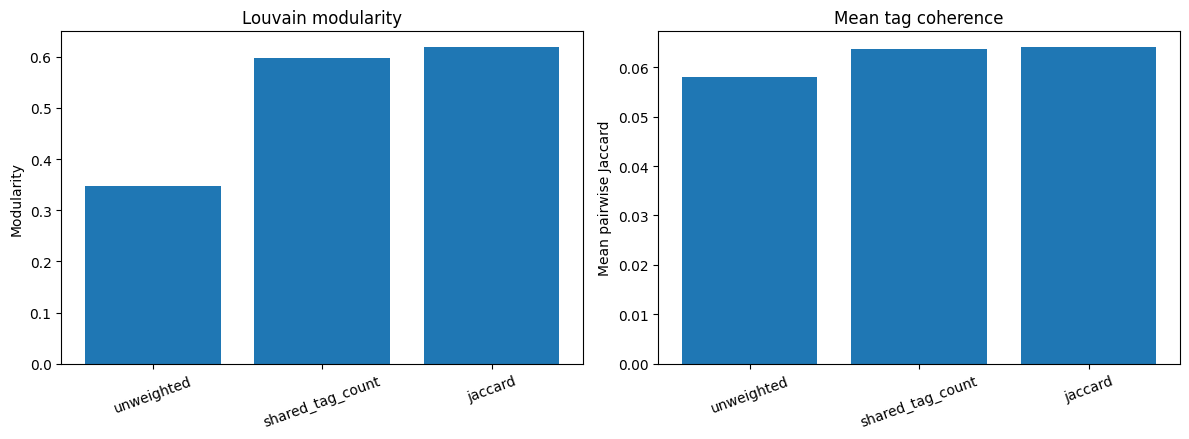

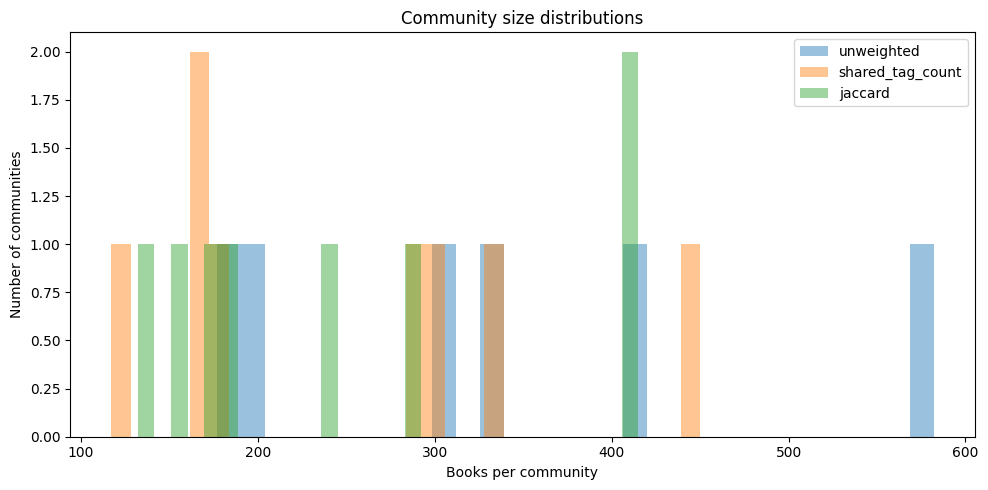

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(summary_df["graph"], summary_df["modularity"])
axes[0].set_title("Louvain modularity")
axes[0].set_ylabel("Modularity")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(summary_df["graph"], summary_df["mean_tag_coherence"])
axes[1].set_title("Mean tag coherence")
axes[1].set_ylabel("Mean pairwise Jaccard")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_modularity_and_tag_coherence.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for name in graphs:
    sizes = community_metrics.loc[community_metrics.graph == name, "size"]
    ax.hist(sizes, bins=30, alpha=0.45, label=name)
ax.set_title("Community size distributions")
ax.set_xlabel("Books per community")
ax.set_ylabel("Number of communities")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_community_size_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Add book titles and visualize a small subgraph


Largest communities — unweighted
Community 3, size=582


,title,authors,average_rating
905,Skinny Bitch,"Rory Freedman, Kim Barnouin",3.34
906,For Women Only: What You Need to Know about th...,Shaunti Feldhahn,4.06
907,Death by Black Hole - And Other Cosmic Quandaries,Neil deGrasse Tyson,4.11
908,Not a Fan: Becoming a Completely Committed Fol...,Kyle Idleman,4.23
909,The Mastery of Love: A Practical Guide to the ...,Miguel Ruiz,4.25
910,Experiencing God: Knowing and Doing the Will o...,"Henry T. Blackaby, Claude V. King, Richard Bla...",4.32
911,"Women, Food and God: An Unexpected Path to Alm...",Geneen Roth,3.62
912,Bringing Up Bébé: One American Mother Discover...,"Pamela Druckerman, Abby Craden",3.95


Community 0, size=407


,title,authors,average_rating
0,At the Mountains of Madness and Other Tales of...,H.P. Lovecraft,4.25
1,Crush,Richard Siken,4.33
2,"The Long Goodbye (Philip Marlowe, #6)",Raymond Chandler,4.23
3,The Magic Mountain,"Thomas Mann, John E. Woods",4.14
4,"Twenty Years After (The D'Artagnan Romances, #2)","Alexandre Dumas, David Coward, Auguste Maquet",4.01
5,La Dame aux Camélias,"Alexandre Dumas fils, David Coward",3.97
6,The Painted Bird,Jerzy Kosiński,3.94
7,The Waste Land and Other Poems,T.S. Eliot,4.23


Community 5, size=336


,title,authors,average_rating
1664,"The High Window (Philip Marlowe, #3)",Raymond Chandler,4.08
1665,"Startide Rising (The Uplift Saga, #2)",David Brin,4.04
1666,The Mothers,Brit Bennett,3.87
1667,"Maximum Security (Cherub, #3)",Robert Muchamore,4.24
1668,Servant of the Shard (Forgotten Realms: Paths ...,R.A. Salvatore,4.15
1669,"Heat Lightning (Virgil Flowers, #2)",John Sandford,4.16
1670,The Icewind Dale Trilogy Collector's Edition (...,R.A. Salvatore,4.28
1671,"The Last Patriot (Scot Harvath, #7)",Brad Thor,4.16


... (8 outputs left out)

Community 5, size=410


,title,authors,average_rating
5058,Skinny Bitch,"Rory Freedman, Kim Barnouin",3.34
5059,The Mothers,Brit Bennett,3.87
5060,Empire of the Summer Moon: Quanah Parker and t...,S.C. Gwynne,4.13
5061,Andy Goldsworthy: A Collaboration with Nature,Andy Goldsworthy,3.95
5062,Death by Black Hole - And Other Cosmic Quandaries,Neil deGrasse Tyson,4.11
5063,2 States: The Story of My Marriage,Chetan Bhagat,3.42
5064,Vincent Van Gogh: The Complete Paintings,"Rainer Metzger, Ingo F. Walther",4.14
5065,"I, Elizabeth",Rosalind Miles,4.01


Community 7, size=292


,title,authors,average_rating
5708,"Falling into You (Falling, #1)",Jasinda Wilder,4.04
5709,"Dark Demon (Dark, #16)",Christine Feehan,4.34
5710,"Starcrossed (Starcrossed, #1)",Josephine Angelini,4.08
5711,Trouble,Samantha Towle,4.00
5712,"Feral Sins (The Phoenix Pack, #1)",Suzanne Wright,4.12
5713,"Reasonable Doubt: Volume 3 (Reasonable Doubt, #3)",Whitney G.,4.19
5714,"It Happened One Autumn (Wallflowers, #2)",Lisa Kleypas,4.15
5715,"Dominic (Slater Brothers, #1)",L.A. Casey,4.08


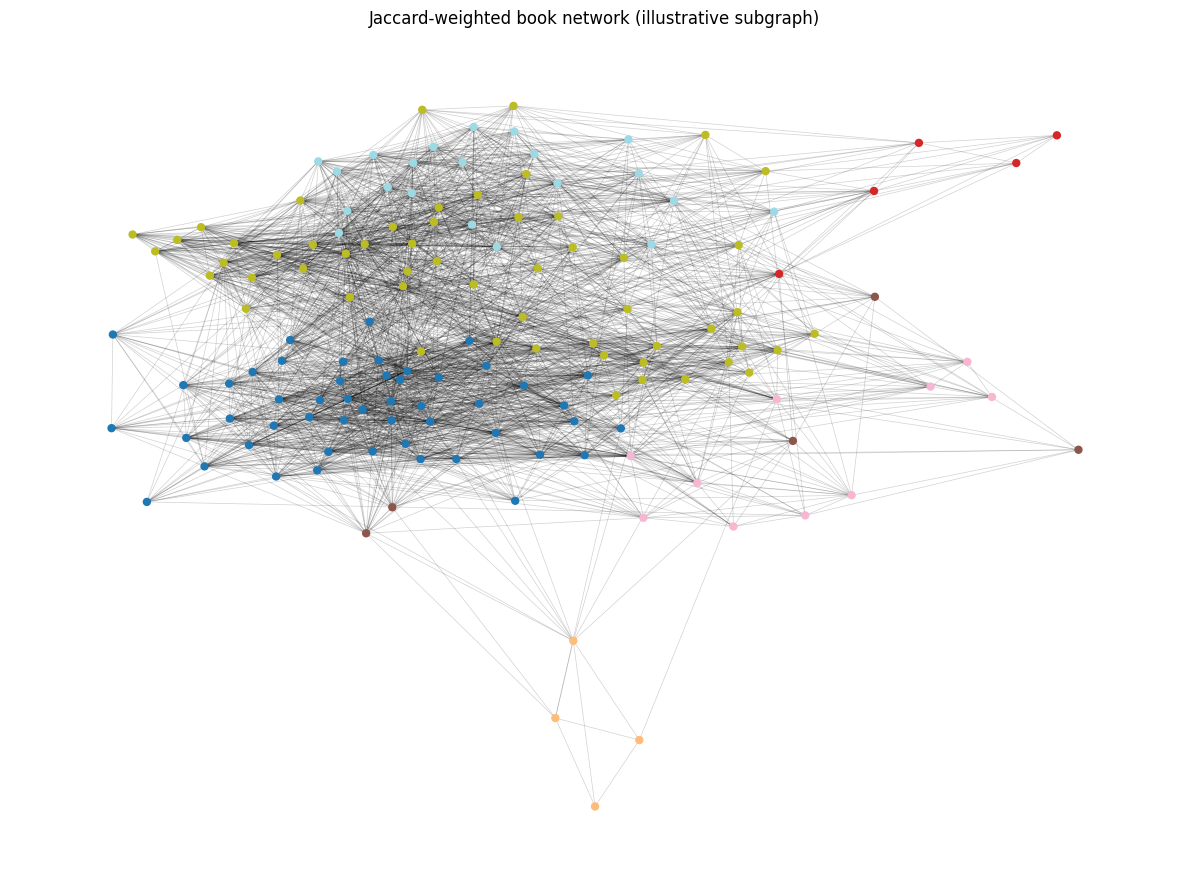

In [11]:
book_lookup = books.rename(columns={"book_id": "goodreads_book_id"})
assignments_named = assignments.merge(
    book_lookup, on="goodreads_book_id", how="left", validate="many_to_one"
)
assignments_named.to_csv(TABLE_DIR / "02_community_assignments_with_titles.csv", index=False)

for name in graphs:
    print(f"\nLargest communities — {name}")
    sizes = assignments_named[assignments_named.graph == name].groupby("community_id").size().sort_values(ascending=False)
    for cid in sizes.head(3).index:
        print(f"Community {cid}, size={sizes.loc[cid]}")
        display(assignments_named[
            (assignments_named.graph == name) & (assignments_named.community_id == cid)
        ][["title", "authors", "average_rating"]].head(8))

# Plot up to 150 nodes from the largest connected component of the Jaccard graph.
G = graphs["jaccard"]
largest_component = max(nx.connected_components(G), key=len)
vis_nodes = sorted(largest_component)[:150]
G_vis = G.subgraph(vis_nodes).copy()
j_assign = assignments[assignments.graph == "jaccard"].set_index("goodreads_book_id")["community_id"].to_dict()
colors = [j_assign.get(node, -1) for node in G_vis.nodes()]
plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G_vis, seed=RANDOM_STATE, weight="weight")
nx.draw_networkx_edges(G_vis, pos, alpha=0.18, width=0.5)
nx.draw_networkx_nodes(G_vis, pos, node_size=25, node_color=colors, cmap=plt.cm.tab20)
plt.title("Jaccard-weighted book network (illustrative subgraph)")
plt.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_jaccard_network_subgraph.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Save experiment configuration and validate

In [12]:
config = {
    "random_state": RANDOM_STATE,
    "max_books": MAX_BOOKS,
    "min_tag_book_frequency": MIN_TAG_BOOK_FREQUENCY,
    "max_tag_book_frequency": MAX_TAG_BOOK_FREQUENCY,
    "min_tags_per_book": MIN_TAGS_PER_BOOK,
    "max_tags_per_book": MAX_TAGS_PER_BOOK,
    "generic_tags_excluded": sorted(GENERIC_TAGS),
    "selected_books": len(selected_ids),
    "candidate_edges": len(edges),
    "graphs": {
        name: {
            "nodes": G.number_of_nodes(),
            "edges": G.number_of_edges(),
            "communities": len(results[name]["communities"]),
            "modularity": results[name]["modularity"]
        } for name, G in graphs.items()
    }
}
with open(TABLE_DIR / "02_experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

assert set(graphs["unweighted"].nodes()) == set(graphs["shared_tag_count"].nodes()) == set(graphs["jaccard"].nodes())
assert set(graphs["unweighted"].edges()) == set(graphs["shared_tag_count"].edges()) == set(graphs["jaccard"].edges())
assert all(assignments.groupby("graph")["goodreads_book_id"].nunique().eq(len(selected_ids)))
print("PASS: all graphs have identical nodes and candidate edges.")
print("PASS: each selected book has one assignment in each graph.")
print("Saved tables to:", TABLE_DIR)
print("Saved figures to:", FIGURE_DIR)

PASS: all graphs have identical nodes and candidate edges.
PASS: each selected book has one assignment in each graph.
Saved tables to: C:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables
Saved figures to: C:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\figures


## 12. Interpretation notes (complete after execution)

Use the values actually produced by this notebook to answer:
1. Which method produced the most communities and the largest community?
2. How did modularity vary by weighting method?
3. Which method had the highest mean tag coherence?
4. Did the method with the highest modularity also have the highest coherence?
5. What limitations arise from tag filtering and the deterministic book subset?

Limitations to report: the first experiment uses a subset, filtering affects graph structure, coherence is sampled for large communities, and Louvain is heuristic. Do not claim superiority from modularity alone.

## 13. Robustness Checks

This section examines whether the observed community-detection results
remain stable across random seeds, alternative book samples, and tag
filtering thresholds.

The checks use the same three edge-weighting strategies:
- Unweighted
- Shared-tag count
- Jaccard similarity

Selected book IDs: 2000
Graph configurations: ['unweighted', 'shared_tag_count', 'jaccard']
Tables directory: C:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables
Figures directory: C:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\figures
Prepared unique book-tag relationships: 999904

Random-seed stability summary


,runs,mean_communities,std_communities,min_modularity,mean_modularity,std_modularity,max_modularity
graph,,,,,,,
jaccard,5,7.4,0.54772,0.61844,0.62054,0.00221,0.62291
shared_tag_count,5,7.6,0.54772,0.59679,0.59893,0.00248,0.60234
unweighted,5,5.8,0.44721,0.34090,0.34684,0.00335,0.34889



Saved seed-level assignments:
(30000, 4)
        graph  seed  goodreads_book_id  community_id
0  unweighted     7           17448960             0
1  unweighted     7            3097601             0
2  unweighted     7             184324             0
3  unweighted     7            9462795             0
4  unweighted     7           17257484             0


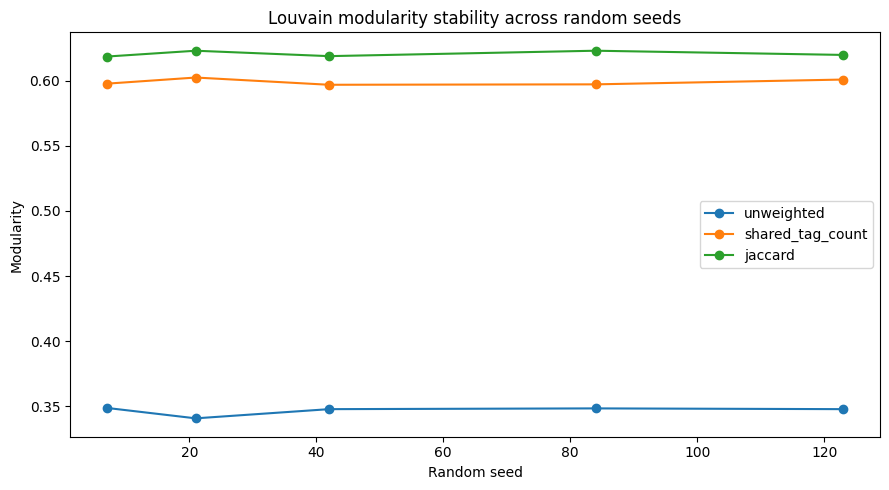


Alternative-sample experiment
Sampling seed: 2026
Books sampled before tag filtering: 2000
Books retained after tag filtering: 2000


,experiment,graph,nodes,edges,communities,modularity,largest_community_size,median_community_size
0,alternative_sample,unweighted,2000,327388,6,0.34795,582,321.0
1,alternative_sample,shared_tag_count,2000,327388,8,0.59679,450,233.0
2,alternative_sample,jaccard,2000,327388,8,0.61875,415,210.5



Tag-frequency sensitivity results


,experiment,graph,nodes,edges,communities,modularity,largest_community_size,median_community_size,max_tag_book_frequency
2,tag_frequency_sensitivity,jaccard,1995,119852,14,0.68641,264,135.0,100
1,tag_frequency_sensitivity,shared_tag_count,1995,119852,14,0.65050,290,130.0,100
0,tag_frequency_sensitivity,unweighted,1995,119852,7,0.47194,427,295.0,100
5,tag_frequency_sensitivity,jaccard,2000,327388,8,0.61875,415,210.5,300
4,tag_frequency_sensitivity,shared_tag_count,2000,327388,8,0.59679,450,233.0,300
3,tag_frequency_sensitivity,unweighted,2000,327388,6,0.34795,582,321.0,300
8,tag_frequency_sensitivity,jaccard,923,101599,9,0.53836,203,78.0,500
7,tag_frequency_sensitivity,shared_tag_count,923,101599,8,0.50979,235,80.5,500
6,tag_frequency_sensitivity,unweighted,923,101599,6,0.25919,203,179.0,500


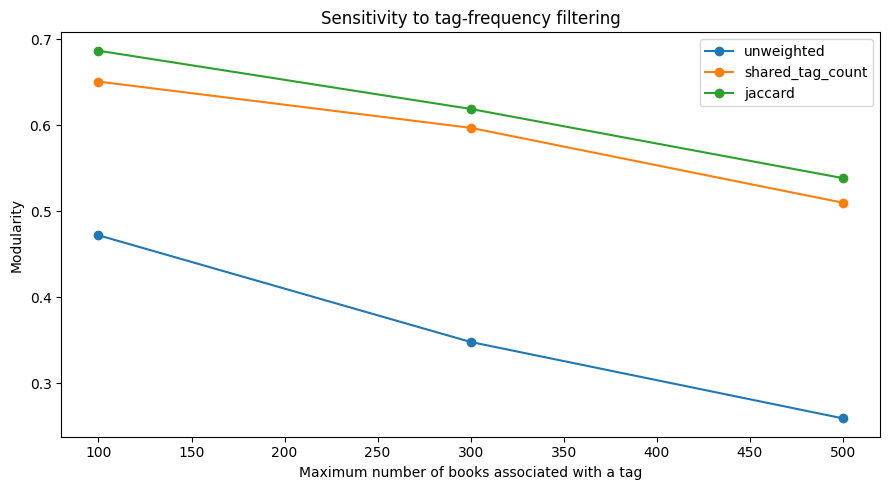


ROBUSTNESS CHECKS COMPLETED
Seed results: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\02_seed_stability_results.csv
Alternative sample: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\02_alternative_sample_results.csv
Filtering sensitivity: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\02_filter_sensitivity_results.csv
Configuration: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\02_robustness_config.json
Figures folder: C:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\figures


In [21]:

# ============================================================
# SECTION 15: ROBUSTNESS CHECKS
# Goodbooks-10k Graph Theory Research
# ============================================================

import json
import time
from itertools import combinations
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# ------------------------------------------------------------
# 15.1: Confirm required objects and output folders
# ------------------------------------------------------------


# ------------------------------------------------------------
# 15.1: Confirm required objects and output folders
# ------------------------------------------------------------

required_variables = [
    "tag_rows",
    "graphs",
    "MAX_BOOKS",
    "MIN_TAG_BOOK_FREQUENCY",
    "MAX_TAG_BOOK_FREQUENCY",
    "MIN_TAGS_PER_BOOK",
    "MAX_TAGS_PER_BOOK",
    "RANDOM_STATE",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Run the earlier Notebook 2 cells first. Missing variables: "
        + ", ".join(missing_variables)
    )

# Recover selected IDs from the existing graph if necessary.
if "selected_book_ids" not in globals():
    selected_book_ids = list(graphs["unweighted"].nodes())

print("Selected book IDs:", len(selected_book_ids))
print("Graph configurations:", list(graphs.keys()))

# Output folders
if "TABLE_DIR" not in globals():
    TABLE_DIR = Path("outputs") / "tables"

if "FIGURE_DIR" not in globals():
    FIGURE_DIR = Path("outputs") / "figures"

TABLE_DIR = Path(TABLE_DIR)
FIGURE_DIR = Path(FIGURE_DIR)

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Tables directory:", TABLE_DIR.resolve())
print("Figures directory:", FIGURE_DIR.resolve())

# ------------------------------------------------------------
# 15.2: Prepare tag rows robustly
# ------------------------------------------------------------

eligible_tag_rows = tag_rows.copy()

# Ensure required identifiers exist.
required_tag_columns = {"goodreads_book_id", "tag_id"}
missing_columns = required_tag_columns - set(
    eligible_tag_rows.columns
)

if missing_columns:
    raise ValueError(
        "tag_rows is missing required columns: "
        + str(missing_columns)
    )

eligible_tag_rows["goodreads_book_id"] = pd.to_numeric(
    eligible_tag_rows["goodreads_book_id"],
    errors="coerce"
)
eligible_tag_rows["tag_id"] = pd.to_numeric(
    eligible_tag_rows["tag_id"],
    errors="coerce"
)

eligible_tag_rows = eligible_tag_rows.dropna(
    subset=["goodreads_book_id", "tag_id"]
).copy()

eligible_tag_rows["goodreads_book_id"] = (
    eligible_tag_rows["goodreads_book_id"].astype(int)
)
eligible_tag_rows["tag_id"] = (
    eligible_tag_rows["tag_id"].astype(int)
)

# Calculate how many distinct books have each tag.
if "tag_frequency_books" not in eligible_tag_rows.columns:
    tag_frequency = (
        eligible_tag_rows.groupby("tag_id")["goodreads_book_id"]
        .nunique()
        .rename("tag_frequency_books")
    )
    eligible_tag_rows = eligible_tag_rows.join(
        tag_frequency, on="tag_id"
    )

# Obtain tag names if they are not already included.
if "tag_name" not in eligible_tag_rows.columns:
    processed_tags_path = (
        Path("data") / "processed" / "tags_clean.csv"
    )

    if processed_tags_path.exists():
        tags_lookup = pd.read_csv(processed_tags_path)
    else:
        tags_lookup = None

    if tags_lookup is not None:
        if {"tag_id", "tag_name"}.issubset(tags_lookup.columns):
            eligible_tag_rows = eligible_tag_rows.merge(
                tags_lookup[["tag_id", "tag_name"]].drop_duplicates(
                    "tag_id"
                ),
                on="tag_id",
                how="left"
            )
        else:
            eligible_tag_rows["tag_name"] = ""

    else:
        eligible_tag_rows["tag_name"] = ""

if "tag_name_normalized" not in eligible_tag_rows.columns:
    eligible_tag_rows["tag_name_normalized"] = (
        eligible_tag_rows["tag_name"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

# Avoid repeated book-tag rows.
eligible_tag_rows = eligible_tag_rows.drop_duplicates(
    ["goodreads_book_id", "tag_id"]
).copy()

# Exclude generic tags only when the original notebook defined
# a generic-tag list. Otherwise, use the original frequency rules.
if "GENERIC_TAGS" not in globals():
    GENERIC_TAGS = set()

GENERIC_TAGS = {
    str(tag).strip().lower() for tag in GENERIC_TAGS
}

print("Prepared unique book-tag relationships:",
      len(eligible_tag_rows))


# ------------------------------------------------------------
# 15.3: Experiment A — seed stability + community assignments
# ------------------------------------------------------------

ROBUSTNESS_SEEDS = [7, 21, 42, 84, 123]

stability_rows = []
seed_assignment_rows = []

for graph_name, G in graphs.items():

    weight_arg = None if graph_name == "unweighted" else "weight"

    for seed in ROBUSTNESS_SEEDS:
        start_time = time.time()

        communities = nx.community.louvain_communities(
            G,
            weight=weight_arg,
            resolution=1,
            seed=seed
        )

        modularity = nx.community.modularity(
            G,
            communities,
            weight=weight_arg
        )

        stability_rows.append({
            "graph": graph_name,
            "seed": seed,
            "nodes": G.number_of_nodes(),
            "edges": G.number_of_edges(),
            "communities": len(communities),
            "modularity": modularity,
            "runtime_seconds": time.time() - start_time
        })

        # Save each book's community assignment for this run.
        for community_id, members in enumerate(communities):
            for book_id in members:
                seed_assignment_rows.append({
                    "graph": graph_name,
                    "seed": seed,
                    "goodreads_book_id": book_id,
                    "community_id": community_id
                })

seed_results_df = pd.DataFrame(stability_rows)

seed_results_df.to_csv(
    TABLE_DIR / "02_seed_stability_results.csv",
    index=False
)

seed_assignments_df = pd.DataFrame(seed_assignment_rows)

seed_assignments_df.to_csv(
    TABLE_DIR / "02_seed_community_assignments.csv",
    index=False
)

seed_summary_df = (
    seed_results_df.groupby("graph")
    .agg(
        runs=("seed", "count"),
        mean_communities=("communities", "mean"),
        std_communities=("communities", "std"),
        min_modularity=("modularity", "min"),
        mean_modularity=("modularity", "mean"),
        std_modularity=("modularity", "std"),
        max_modularity=("modularity", "max")
    )
    .round(5)
)

print("\nRandom-seed stability summary")
display(seed_summary_df)

print("\nSaved seed-level assignments:")
print(seed_assignments_df.shape)
print(seed_assignments_df.head())

plt.figure(figsize=(9, 5))

for graph_name in graphs:
    subset = seed_results_df[
        seed_results_df["graph"] == graph_name
    ].sort_values("seed")

    plt.plot(
        subset["seed"],
        subset["modularity"],
        marker="o",
        label=graph_name
    )

plt.xlabel("Random seed")
plt.ylabel("Modularity")
plt.title("Louvain modularity stability across random seeds")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "02_seed_stability.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 15.4: Shared function to build three graph configurations
# ------------------------------------------------------------

def build_weighted_graphs(book_to_tags):
    """
    Build unweighted, shared-tag-count, and Jaccard graphs
    from a dictionary: book ID -> set of tag IDs.
    """

    tag_to_books = {}

    for book_id, tag_set in book_to_tags.items():
        for tag_id in tag_set:
            tag_to_books.setdefault(tag_id, []).append(book_id)

    pair_shared = Counter()

    for book_ids in tag_to_books.values():
        unique_ids = sorted(set(book_ids))

        for a, b in combinations(unique_ids, 2):
            pair_shared[(a, b)] += 1

    result_graphs = {
        "unweighted": nx.Graph(),
        "shared_tag_count": nx.Graph(),
        "jaccard": nx.Graph()
    }

    node_ids = sorted(book_to_tags)

    for G in result_graphs.values():
        G.add_nodes_from(node_ids)

    for (a, b), shared_count in pair_shared.items():

        union_size = len(book_to_tags[a] | book_to_tags[b])

        if union_size == 0:
            continue

        jaccard_weight = shared_count / union_size

        result_graphs["unweighted"].add_edge(
            a, b, weight=1.0
        )
        result_graphs["shared_tag_count"].add_edge(
            a, b, weight=float(shared_count)
        )
        result_graphs["jaccard"].add_edge(
            a, b, weight=float(jaccard_weight)
        )

    return result_graphs


def evaluate_graphs(graph_dict, experiment_name, seed=42):
    """Calculate core graph and community metrics."""

    rows = []

    for graph_name, G in graph_dict.items():

        weight_arg = None if graph_name == "unweighted" else "weight"

        if G.number_of_nodes() == 0 or G.number_of_edges() == 0:
            rows.append({
                "experiment": experiment_name,
                "graph": graph_name,
                "nodes": G.number_of_nodes(),
                "edges": G.number_of_edges(),
                "communities": np.nan,
                "modularity": np.nan
            })
            continue

        communities = nx.community.louvain_communities(
            G,
            weight=weight_arg,
            resolution=1,
            seed=seed
        )

        modularity = nx.community.modularity(
            G, communities, weight=weight_arg
        )

        rows.append({
            "experiment": experiment_name,
            "graph": graph_name,
            "nodes": G.number_of_nodes(),
            "edges": G.number_of_edges(),
            "communities": len(communities),
            "modularity": modularity,
            "largest_community_size": max(
                len(c) for c in communities
            ),
            "median_community_size": float(
                np.median([len(c) for c in communities])
            )
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 15.5: Experiment B — alternative reproducible book sample
# ------------------------------------------------------------

ALT_SAMPLE_SEED = 2026
ALT_SAMPLE_SIZE = min(int(MAX_BOOKS), len(selected_book_ids))

eligible_ids = np.array(
    sorted(set(int(x) for x in selected_book_ids))
)

rng = np.random.default_rng(ALT_SAMPLE_SEED)

if len(eligible_ids) < 2:
    raise ValueError("Not enough eligible book IDs for sampling.")

sample_size = min(ALT_SAMPLE_SIZE, len(eligible_ids))

alternative_ids = set(
    rng.choice(
        eligible_ids,
        size=sample_size,
        replace=False
    ).tolist()
)

# Start from unique relationships and use the same frequency
# and per-book tag limits as the original experiment.
alt_rows = eligible_tag_rows[
    eligible_tag_rows["goodreads_book_id"].isin(alternative_ids)
    & (
        eligible_tag_rows["tag_frequency_books"]
        >= MIN_TAG_BOOK_FREQUENCY
    )
    & (
        eligible_tag_rows["tag_frequency_books"]
        <= MAX_TAG_BOOK_FREQUENCY
    )
    & (
        ~eligible_tag_rows["tag_name_normalized"].isin(
            GENERIC_TAGS
        )
    )
].copy()

alt_book_to_tags = (
    alt_rows.groupby("goodreads_book_id")["tag_id"]
    .apply(lambda values: set(values.astype(int)))
    .to_dict()
)

alt_book_to_tags = {
    int(book_id): tag_set
    for book_id, tag_set in alt_book_to_tags.items()
    if MIN_TAGS_PER_BOOK <= len(tag_set) <= MAX_TAGS_PER_BOOK
}

print("\nAlternative-sample experiment")
print("Sampling seed:", ALT_SAMPLE_SEED)
print("Books sampled before tag filtering:", sample_size)
print("Books retained after tag filtering:", len(alt_book_to_tags))

if len(alt_book_to_tags) < 2:
    raise ValueError(
        "Alternative sample retained fewer than two books. "
        "Review the filtering rules."
    )

alt_graphs = build_weighted_graphs(alt_book_to_tags)

alt_sample_results_df = evaluate_graphs(
    alt_graphs,
    experiment_name="alternative_sample",
    seed=RANDOM_STATE
)

alt_sample_results_df.to_csv(
    TABLE_DIR / "02_alternative_sample_results.csv",
    index=False
)

display(alt_sample_results_df.round(5))


# ------------------------------------------------------------
# 15.6: Experiment C — sensitivity to tag-frequency cutoff
# ------------------------------------------------------------

# Use three distinct cutoffs where possible.
FREQUENCY_CUTOFFS = sorted(set([
    max(int(MIN_TAG_BOOK_FREQUENCY), 100),
    int(MAX_TAG_BOOK_FREQUENCY),
    500
]))

FREQUENCY_CUTOFFS = [
    cutoff for cutoff in FREQUENCY_CUTOFFS
    if cutoff >= MIN_TAG_BOOK_FREQUENCY
]

# The selected IDs are kept fixed in this experiment.
# Only the upper tag-frequency cutoff changes.
sensitivity_results = []

for max_freq in FREQUENCY_CUTOFFS:

    filtered = eligible_tag_rows[
        eligible_tag_rows["goodreads_book_id"].isin(
            set(int(x) for x in selected_book_ids)
        )
        & (
            eligible_tag_rows["tag_frequency_books"]
            >= MIN_TAG_BOOK_FREQUENCY
        )
        & (
            eligible_tag_rows["tag_frequency_books"]
            <= max_freq
        )
        & (
            ~eligible_tag_rows["tag_name_normalized"].isin(
                GENERIC_TAGS
            )
        )
    ].copy()

    cutoff_book_to_tags = (
        filtered.groupby("goodreads_book_id")["tag_id"]
        .apply(lambda values: set(values.astype(int)))
        .to_dict()
    )

    cutoff_book_to_tags = {
        int(book_id): tag_set
        for book_id, tag_set in cutoff_book_to_tags.items()
        if MIN_TAGS_PER_BOOK <= len(tag_set) <= MAX_TAGS_PER_BOOK
    }

    if len(cutoff_book_to_tags) < 2:
        print(
            f"Skipping cutoff {max_freq}: "
            "fewer than two eligible books."
        )
        continue

    cutoff_graphs = build_weighted_graphs(cutoff_book_to_tags)

    cutoff_results = evaluate_graphs(
        cutoff_graphs,
        experiment_name="tag_frequency_sensitivity",
        seed=RANDOM_STATE
    )

    cutoff_results["max_tag_book_frequency"] = max_freq

    sensitivity_results.append(cutoff_results)

if sensitivity_results:
    sensitivity_df = pd.concat(
        sensitivity_results,
        ignore_index=True
    )

    sensitivity_df.to_csv(
        TABLE_DIR / "02_filter_sensitivity_results.csv",
        index=False
    )

    print("\nTag-frequency sensitivity results")
    display(
        sensitivity_df.sort_values(
            ["max_tag_book_frequency", "graph"]
        ).round(5)
    )

    plt.figure(figsize=(9, 5))

    for graph_name in [
        "unweighted", "shared_tag_count", "jaccard"
    ]:
        subset = sensitivity_df[
            sensitivity_df["graph"] == graph_name
        ].sort_values("max_tag_book_frequency")

        plt.plot(
            subset["max_tag_book_frequency"],
            subset["modularity"],
            marker="o",
            label=graph_name
        )

    plt.xlabel("Maximum number of books associated with a tag")
    plt.ylabel("Modularity")
    plt.title("Sensitivity to tag-frequency filtering")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / "02_filter_sensitivity.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()

else:
    sensitivity_df = pd.DataFrame()
    print("No valid filtering-sensitivity experiments completed.")


# ------------------------------------------------------------
# 15.7: Save combined results and configuration
# ------------------------------------------------------------

alt_sample_results_df.to_csv(
    TABLE_DIR / "02_alternative_sample_results.csv",
    index=False
)

robustness_config = {
    "random_seeds": ROBUSTNESS_SEEDS,
    "alternative_sample_seed": ALT_SAMPLE_SEED,
    "alternative_sample_size_requested": sample_size,
    "alternative_sample_books_retained": len(alt_book_to_tags),
    "frequency_cutoffs": FREQUENCY_CUTOFFS,
    "weighting_methods": list(graphs.keys()),
    "notes": [
        "Louvain is heuristic and may vary by random seed.",
        "Alternative sample results depend on filtering rules.",
        "Frequency sensitivity changes the retained tag set.",
        "Modularity should be interpreted alongside tag coherence."
    ]
}

with open(
    TABLE_DIR / "02_robustness_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(robustness_config, file, indent=2)

print("\n" + "=" * 60)
print("ROBUSTNESS CHECKS COMPLETED")
print("=" * 60)

print("Seed results:",
      TABLE_DIR / "02_seed_stability_results.csv")
print("Alternative sample:",
      TABLE_DIR / "02_alternative_sample_results.csv")
print("Filtering sensitivity:",
      TABLE_DIR / "02_filter_sensitivity_results.csv")
print("Configuration:",
      TABLE_DIR / "02_robustness_config.json")
print("Figures folder:", FIGURE_DIR.resolve())


In [22]:
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

# Load the saved community assignments.
seed_assignments = pd.read_csv(
    TABLE_DIR / "02_seed_community_assignments.csv"
)

methods = ["unweighted", "shared_tag_count", "jaccard"]
ari_seed_rows = []

for seed in ROBUSTNESS_SEEDS:

    seed_data = seed_assignments[
        seed_assignments["seed"] == seed
    ]

    wide = seed_data.pivot(
        index="goodreads_book_id",
        columns="graph",
        values="community_id"
    )

    for method_a, method_b in combinations(methods, 2):

        pair = wide[[method_a, method_b]].dropna()

        ari = adjusted_rand_score(
            pair[method_a],
            pair[method_b]
        )

        ari_seed_rows.append({
            "seed": seed,
            "method_a": method_a,
            "method_b": method_b,
            "books_compared": len(pair),
            "adjusted_rand_index": ari
        })

ari_seed_df = pd.DataFrame(ari_seed_rows)

ari_seed_df.to_csv(
    TABLE_DIR / "02_seed_ari_comparison.csv",
    index=False
)

display(
    ari_seed_df.round(5)
)

ari_summary_df = (
    ari_seed_df.groupby(["method_a", "method_b"])
    .agg(
        mean_ari=("adjusted_rand_index", "mean"),
        std_ari=("adjusted_rand_index", "std"),
        min_ari=("adjusted_rand_index", "min"),
        max_ari=("adjusted_rand_index", "max")
    )
    .reset_index()
    .round(5)
)

print("\nARI summary across random seeds")
display(ari_summary_df)

ari_summary_df.to_csv(
    TABLE_DIR / "02_seed_ari_summary.csv",
    index=False
)

,seed,method_a,method_b,books_compared,adjusted_rand_index
0,7,unweighted,shared_tag_count,2000,0.59510
1,7,unweighted,jaccard,2000,0.58599
2,7,shared_tag_count,jaccard,2000,0.83813
3,21,unweighted,shared_tag_count,2000,0.74801
4,21,unweighted,jaccard,2000,0.71568
5,21,shared_tag_count,jaccard,2000,0.92957
6,42,unweighted,shared_tag_count,2000,0.63828
7,42,unweighted,jaccard,2000,0.61142
8,42,shared_tag_count,jaccard,2000,0.81854
9,84,unweighted,shared_tag_count,2000,0.64366



ARI summary across random seeds


,method_a,method_b,mean_ari,std_ari,min_ari,max_ari
0,shared_tag_count,jaccard,0.84245,0.07476,0.73413,0.92957
1,unweighted,jaccard,0.68766,0.08400,0.58599,0.76781
2,unweighted,shared_tag_count,0.68021,0.07764,0.59510,0.77600


In [14]:

from pathlib import Path
import pandas as pd
import numpy as np

# Locate project folders relative to the notebook
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
TABLE_DIR = OUTPUT_DIR / "tables"

print("Project root:", PROJECT_ROOT.resolve())
print("Processed data exists:", PROCESSED_DIR.exists())
print("Tables directory exists:", TABLE_DIR.exists())

# Check saved experiment files
for filename in [
    "02_seed_stability_results.csv",
    "02_alternative_sample_results.csv",
    "02_filter_sensitivity_results.csv",
]:
    filepath = TABLE_DIR / filename
    print(f"{filename}: {'FOUND' if filepath.exists() else 'NOT FOUND'}")

# Read and display the saved alternative-sample results
alternative_file = TABLE_DIR / "02_alternative_sample_results.csv"

if alternative_file.exists():
    alternative_results = pd.read_csv(alternative_file)
    display(alternative_results)
else:
    print("Alternative-sample results CSV was not found.")


Project root: C:\Users\Nethmi\Desktop\goodbooks-graph-research
Processed data exists: True
Tables directory exists: True
02_seed_stability_results.csv: FOUND
02_alternative_sample_results.csv: FOUND
02_filter_sensitivity_results.csv: FOUND


,experiment,graph,nodes,edges,communities,modularity,largest_community_size,median_community_size
0,alternative_sample,unweighted,2000,327388,6,0.347950,582,321.0
1,alternative_sample,shared_tag_count,2000,327388,8,0.596787,450,233.0
2,alternative_sample,jaccard,2000,327388,8,0.618754,415,210.5


In [23]:
from itertools import combinations
from sklearn.metrics import adjusted_rand_score
import pandas as pd

seed_assignments = pd.read_csv(
    TABLE_DIR / "02_seed_community_assignments.csv"
)

within_seed_rows = []

for graph_name in ["unweighted", "shared_tag_count", "jaccard"]:

    method_data = seed_assignments[
        seed_assignments["graph"] == graph_name
    ]

    wide = method_data.pivot(
        index="goodreads_book_id",
        columns="seed",
        values="community_id"
    )

    # Compare all pairs of seeds within this method.
    for seed_a, seed_b in combinations(wide.columns, 2):

        pair = wide[[seed_a, seed_b]].dropna()

        ari = adjusted_rand_score(
            pair[seed_a],
            pair[seed_b]
        )

        within_seed_rows.append({
            "graph": graph_name,
            "seed_a": seed_a,
            "seed_b": seed_b,
            "books_compared": len(pair),
            "adjusted_rand_index": ari
        })

within_seed_df = pd.DataFrame(within_seed_rows)

within_seed_df.to_csv(
    TABLE_DIR / "02_within_method_seed_ari.csv",
    index=False
)

within_seed_summary = (
    within_seed_df.groupby("graph")
    .agg(
        comparisons=("adjusted_rand_index", "count"),
        mean_ari=("adjusted_rand_index", "mean"),
        std_ari=("adjusted_rand_index", "std"),
        min_ari=("adjusted_rand_index", "min"),
        max_ari=("adjusted_rand_index", "max")
    )
    .reset_index()
    .round(5)
)

display(within_seed_summary)

within_seed_summary.to_csv(
    TABLE_DIR / "02_within_method_seed_ari_summary.csv",
    index=False
)

,graph,comparisons,mean_ari,std_ari,min_ari,max_ari
0,jaccard,10,0.77491,0.10207,0.65946,0.98055
1,shared_tag_count,10,0.84355,0.08005,0.77641,0.97663
2,unweighted,10,0.87261,0.08608,0.75469,1.00000


In [15]:

# ============================================================
# SECTION 16: VERIFY ALTERNATIVE SAMPLE SELECTION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"

# Load the processed book-tag data
tag_file = PROCESSED_DIR / "graph_tag_rows.csv"

if not tag_file.exists():
    raise FileNotFoundError(f"Cannot find {tag_file}")

tag_rows_check = pd.read_csv(tag_file)

print("Processed tag rows:", len(tag_rows_check))
print("Columns:", tag_rows_check.columns.tolist())

# Recover original selected IDs from saved candidate edges.
# This is a diagnostic approximation: nodes without edges
# cannot be recovered from an edge list alone.
edge_file = TABLE_DIR / "02_candidate_edges.csv"

if edge_file.exists():
    edges_check = pd.read_csv(edge_file)
    original_ids = set(edges_check["source"].astype(int))
    original_ids.update(edges_check["target"].astype(int))
    print("Nodes recovered from edge file:", len(original_ids))
else:
    original_ids = set()
    print(
        "Candidate-edge file not found. "
        "We cannot recover the exact original node set from this file."
    )

# Check whether a different sample can be drawn from all books
# represented in the processed tag table.
all_book_ids = np.sort(
    tag_rows_check["goodreads_book_id"].dropna().astype(int).unique()
)

print("All books in processed tag data:", len(all_book_ids))

if len(original_ids) > 0 and len(all_book_ids) > len(original_ids):
    alternative_seed = 2026
    rng = np.random.default_rng(alternative_seed)

    alternative_ids = set(
        rng.choice(
            all_book_ids,
            size=min(2000, len(all_book_ids)),
            replace=False
        ).astype(int)
    )

    overlap = original_ids & alternative_ids

    print("\nAlternative sample diagnostic")
    print("Original edge-recovered nodes:", len(original_ids))
    print("Alternative sample size:", len(alternative_ids))
    print("Overlap:", len(overlap))
    print("Original-only nodes:", len(original_ids - alternative_ids))
    print("Alternative-only nodes:", len(alternative_ids - original_ids))
    print("Same sets:", original_ids == alternative_ids)
else:
    print(
        "\nNot enough information to verify the original sample. "
        "Please locate the candidate-edge CSV or the original "
        "selected-book ID list."
    )


Processed tag rows: 999904
Columns: ['id', 'goodreads_book_id', 'title', 'tag_id', 'tag_name', 'count']
Nodes recovered from edge file: 2000
All books in processed tag data: 10000

Alternative sample diagnostic
Original edge-recovered nodes: 2000
Alternative sample size: 2000
Overlap: 399
Original-only nodes: 1601
Alternative-only nodes: 1601
Same sets: False


In [16]:

from pathlib import Path
from itertools import combinations
from collections import Counter
import json
import random
import time

import pandas as pd
import networkx as nx


# ============================================================
# 1. Locate project folders
# ============================================================

current = Path.cwd()
candidates = [current, *current.parents]

PROJECT_ROOT = next(
    (
        p for p in candidates
        if (p / "data" / "processed" / "graph_tag_rows.csv").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/processed/graph_tag_rows.csv. "
        "Run this cell from your project folder or one of its subfolders."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_TABLES = PROJECT_ROOT / "outputs" / "tables"
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)


# ============================================================
# 2. Load all available book-tag data
# ============================================================

tag_rows = pd.read_csv(PROCESSED_DIR / "graph_tag_rows.csv")

required = {"goodreads_book_id", "tag_id", "tag_name"}
missing = required - set(tag_rows.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

tag_rows = tag_rows.dropna(
    subset=["goodreads_book_id", "tag_id"]
).copy()

tag_rows["goodreads_book_id"] = pd.to_numeric(
    tag_rows["goodreads_book_id"], errors="coerce"
)
tag_rows["tag_id"] = pd.to_numeric(
    tag_rows["tag_id"], errors="coerce"
)

tag_rows = tag_rows.dropna(
    subset=["goodreads_book_id", "tag_id"]
)

tag_rows["goodreads_book_id"] = (
    tag_rows["goodreads_book_id"].astype(int)
)
tag_rows["tag_id"] = tag_rows["tag_id"].astype(int)

# One row per book-tag relationship.
tag_rows = tag_rows.drop_duplicates(
    subset=["goodreads_book_id", "tag_id"]
)

all_book_ids = sorted(tag_rows["goodreads_book_id"].unique())

print("Unique books available:", len(all_book_ids))
print("Unique book-tag relationships:", len(tag_rows))


# ============================================================
# 3. Calculate tag frequency across the FULL dataset
# ============================================================

# Frequency = number of distinct books associated with each tag.
global_tag_frequency = (
    tag_rows.groupby("tag_id")["goodreads_book_id"].nunique()
)

MIN_TAG_BOOK_FREQUENCY = 5
MAX_TAG_BOOK_FREQUENCY = 300
MIN_TAGS_PER_BOOK = 5
MAX_TAGS_PER_BOOK = 40

valid_tag_ids = set(
    global_tag_frequency[
        (global_tag_frequency >= MIN_TAG_BOOK_FREQUENCY)
        & (global_tag_frequency <= MAX_TAG_BOOK_FREQUENCY)
    ].index
)

filtered_rows = tag_rows[
    tag_rows["tag_id"].isin(valid_tag_ids)
].copy()

print("Tags retained by global frequency filter:", len(valid_tag_ids))


# ============================================================
# 4. Select a genuinely different sample from all books
# ============================================================

SAMPLE_SIZE = 2000
SAMPLE_SEED = 2026

if len(all_book_ids) < SAMPLE_SIZE:
    raise ValueError(
        f"Only {len(all_book_ids)} books are available; "
        f"cannot sample {SAMPLE_SIZE}."
    )

rng = random.Random(SAMPLE_SEED)
alternative_book_ids = set(
    rng.sample(all_book_ids, SAMPLE_SIZE)
)

# Recover the original sample IDs from the saved main graph's
# edge file, if available, for an overlap diagnostic.
edge_files = list(OUTPUT_TABLES.glob("*edge*.csv"))
original_book_ids = set()

for edge_file in edge_files:
    try:
        edge_df = pd.read_csv(edge_file, nrows=None)
        for col in edge_df.columns:
            if col.lower() in {
                "source", "target", "source_id", "target_id",
                "book_id", "goodreads_book_id"
            }:
                original_book_ids.update(
                    pd.to_numeric(
                        edge_df[col], errors="coerce"
                    ).dropna().astype(int).tolist()
                )
        if len(original_book_ids) >= SAMPLE_SIZE:
            break
    except Exception:
        continue

overlap = len(original_book_ids & alternative_book_ids)

print("Alternative sample size:", len(alternative_book_ids))
if original_book_ids:
    print("Original edge-file book IDs:", len(original_book_ids))
    print("Overlap with original sample:", overlap)
    print(
        "Overlap percentage:",
        round(100 * overlap / len(original_book_ids), 2), "%"
    )
else:
    print(
        "Original sample IDs could not be recovered automatically. "
        "The alternative sample was still drawn from all available books."
    )

# Save the sample so this experiment is reproducible.
pd.DataFrame({
    "goodreads_book_id": sorted(alternative_book_ids)
}).to_csv(
    OUTPUT_TABLES / "02_alternative_sample_book_ids.csv",
    index=False
)


# ============================================================
# 5. Apply the same tag and per-book filtering rules
# ============================================================

sample_rows = filtered_rows[
    filtered_rows["goodreads_book_id"].isin(alternative_book_ids)
].copy()

book_tag_sets = (
    sample_rows.groupby("goodreads_book_id")["tag_id"]
    .apply(lambda values: set(values))
    .to_dict()
)

eligible_book_tags = {
    book_id: tags
    for book_id, tags in book_tag_sets.items()
    if MIN_TAGS_PER_BOOK <= len(tags) <= MAX_TAGS_PER_BOOK
}

node_ids = sorted(eligible_book_tags)

print("Sampled books:", len(alternative_book_ids))
print("Books passing per-book tag limits:", len(node_ids))

if len(node_ids) < 2:
    raise ValueError(
        "Too few books passed the filtering rules to build a graph."
    )


# ============================================================
# 6. Build all three graphs from the same alternative sample
# ============================================================

tag_to_books = {}

for book_id, tags in eligible_book_tags.items():
    for tag_id in tags:
        tag_to_books.setdefault(tag_id, []).append(book_id)

shared_counts = Counter()

for books_with_tag in tag_to_books.values():
    for book_a, book_b in combinations(sorted(books_with_tag), 2):
        shared_counts[(book_a, book_b)] += 1

G_unweighted = nx.Graph()
G_shared = nx.Graph()
G_jaccard = nx.Graph()

for G in [G_unweighted, G_shared, G_jaccard]:
    G.add_nodes_from(node_ids)

for (book_a, book_b), shared_count in shared_counts.items():
    tags_a = eligible_book_tags[book_a]
    tags_b = eligible_book_tags[book_b]
    union_count = len(tags_a | tags_b)

    jaccard_weight = shared_count / union_count

    G_unweighted.add_edge(book_a, book_b, weight=1)
    G_shared.add_edge(
        book_a, book_b, weight=shared_count
    )
    G_jaccard.add_edge(
        book_a, book_b, weight=jaccard_weight
    )

graphs_alt = {
    "unweighted": G_unweighted,
    "shared_tag_count": G_shared,
    "jaccard": G_jaccard
}

for name, G in graphs_alt.items():
    print(
        f"{name}: nodes={G.number_of_nodes()}, "
        f"edges={G.number_of_edges()}, "
        f"components={nx.number_connected_components(G)}"
    )


# ============================================================
# 7. Run Louvain and calculate comparable metrics
# ============================================================

LOUVAIN_SEED = 42
results = []

for name, G in graphs_alt.items():
    start = time.time()

    if G.number_of_edges() == 0:
        communities = [{node} for node in G.nodes()]
        modularity = 0.0
    else:
        weight_argument = None if name == "unweighted" else "weight"

        communities = nx.community.louvain_communities(
            G,
            weight=weight_argument,
            seed=LOUVAIN_SEED
        )

        modularity = nx.community.modularity(
            G,
            communities,
            weight=weight_argument
        )

    community_sizes = sorted(
        (len(c) for c in communities), reverse=True
    )

    # Mean within-community tag Jaccard similarity.
    # This evaluates tag overlap independently of graph edge weights.
    within_similarities = []

    for community in communities:
        members = list(community)
        if len(members) < 2:
            continue

        for book_a, book_b in combinations(members, 2):
            tags_a = eligible_book_tags[book_a]
            tags_b = eligible_book_tags[book_b]
            union_count = len(tags_a | tags_b)

            if union_count:
                within_similarities.append(
                    len(tags_a & tags_b) / union_count
                )

    mean_tag_coherence = (
        sum(within_similarities) / len(within_similarities)
        if within_similarities else 0.0
    )

    results.append({
        "sample_seed": SAMPLE_SEED,
        "louvain_seed": LOUVAIN_SEED,
        "weighting_method": name,
        "nodes": G.number_of_nodes(),
        "edges": G.number_of_edges(),
        "communities": len(communities),
        "modularity": modularity,
        "largest_community": max(community_sizes, default=0),
        "median_community_size": (
            float(pd.Series(community_sizes).median())
            if community_sizes else 0.0
        ),
        "mean_tag_coherence": mean_tag_coherence,
        "runtime_seconds": time.time() - start
    })

results_df = pd.DataFrame(results)

output_file = (
    OUTPUT_TABLES / "02_alternative_sample_results_corrected.csv"
)
results_df.to_csv(output_file, index=False)

config = {
    "sample_size_requested": SAMPLE_SIZE,
    "sample_seed": SAMPLE_SEED,
    "louvain_seed": LOUVAIN_SEED,
    "min_tag_book_frequency": MIN_TAG_BOOK_FREQUENCY,
    "max_tag_book_frequency": MAX_TAG_BOOK_FREQUENCY,
    "min_tags_per_book": MIN_TAGS_PER_BOOK,
    "max_tags_per_book": MAX_TAGS_PER_BOOK,
    "sampled_books": len(alternative_book_ids),
    "eligible_books": len(node_ids),
    "graph_nodes": {
        name: G.number_of_nodes()
        for name, G in graphs_alt.items()
    },
    "graph_edges": {
        name: G.number_of_edges()
        for name, G in graphs_alt.items()
    }
}

with open(
    OUTPUT_TABLES / "02_alternative_sample_corrected_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, indent=2)

print("\nCORRECTED ALTERNATIVE-SAMPLE RESULTS")
display(results_df.round(5))

print("\nSaved results to:", output_file)
print(
    "Saved alternative sample IDs to:",
    OUTPUT_TABLES / "02_alternative_sample_book_ids.csv"
)


Project root: c:\Users\Nethmi\Desktop\goodbooks-graph-research
Unique books available: 10000
Unique book-tag relationships: 999904
Tags retained by global frequency filter: 8485
Alternative sample size: 2000
Original edge-file book IDs: 2000
Overlap with original sample: 402
Overlap percentage: 20.1 %
Sampled books: 2000
Books passing per-book tag limits: 1818
unweighted: nodes=1818, edges=199203, components=1
shared_tag_count: nodes=1818, edges=199203, components=1
jaccard: nodes=1818, edges=199203, components=1

CORRECTED ALTERNATIVE-SAMPLE RESULTS


,sample_seed,louvain_seed,weighting_method,nodes,edges,communities,modularity,largest_community,median_community_size,mean_tag_coherence,runtime_seconds
0,2026,42,unweighted,1818,199203,6,0.30568,486,297.0,0.01829,2.76392
1,2026,42,shared_tag_count,1818,199203,9,0.47134,307,221.0,0.02522,4.91334
2,2026,42,jaccard,1818,199203,10,0.47328,313,185.5,0.02722,3.56076



Saved results to: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\02_alternative_sample_results_corrected.csv
Saved alternative sample IDs to: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\02_alternative_sample_book_ids.csv


In [18]:
import pandas as pd
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

assignments = pd.read_csv(
    "../outputs/tables/02_community_assignments.csv"
)

# Compare only books that occur in both partitions.
wide = assignments.pivot(
    index="goodreads_book_id",
    columns="graph",
    values="community_id"
)

methods = ["unweighted", "shared_tag_count", "jaccard"]
results = []

for method_a, method_b in combinations(methods, 2):
    pair = wide[[method_a, method_b]].dropna()

    ari = adjusted_rand_score(
        pair[method_a],
        pair[method_b]
    )

    results.append({
        "method_a": method_a,
        "method_b": method_b,
        "books_compared": len(pair),
        "adjusted_rand_index": ari
    })

ari_results = pd.DataFrame(results)
display(ari_results)

ari_results.to_csv(
    "outputs/tables/02_partition_ari_comparison.csv",
    index=False
)

,method_a,method_b,books_compared,adjusted_rand_index
0,unweighted,shared_tag_count,2000,0.638281
1,unweighted,jaccard,2000,0.611422
2,shared_tag_count,jaccard,2000,0.818535


In [19]:
from pathlib import Path

project_root = Path.cwd().parent
tables_dir = project_root / "outputs" / "tables"

print("CSV files available:")
for path in sorted(tables_dir.glob("*.csv")):
    print(path.name)

CSV files available:
02_alternative_sample_book_ids.csv
02_alternative_sample_results.csv
02_alternative_sample_results_corrected.csv
02_candidate_edges.csv
02_community_assignments.csv
02_community_assignments_with_titles.csv
02_community_metrics.csv
02_filter_sensitivity_results.csv
02_graph_comparison_summary.csv
02_seed_stability_results.csv
03_additional_model_results.csv
03_final_five_model_comparison.csv
03_hist_gradient_boosting_results.csv
03_linear_svm_results.csv
03_model_comparison.csv
03_random_forest_metrics.csv
03_rating_prediction_metrics.csv
04_diversity_weight_sensitivity.csv
04_lp_selected_books.csv
04_lp_vs_baseline_comparison.csv
04_top_k_baseline_books.csv


In [20]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent
tables_dir = project_root / "outputs" / "tables"

seed_results = pd.read_csv(
    tables_dir / "02_seed_stability_results.csv"
)

display(seed_results)
print("Columns:", seed_results.columns.tolist())

,graph,seed,nodes,edges,communities,modularity,runtime_seconds
0,unweighted,7,2000,327388,5,0.348891,3.570230
1,unweighted,21,2000,327388,6,0.340901,3.481200
2,unweighted,42,2000,327388,6,0.347950,3.240754
3,unweighted,84,2000,327388,6,0.348530,3.977070
4,unweighted,123,2000,327388,6,0.347950,4.139927
5,shared_tag_count,7,2000,327388,8,0.597640,4.316626
6,shared_tag_count,21,2000,327388,7,0.602341,4.675551
7,shared_tag_count,42,2000,327388,8,0.596787,5.390980
8,shared_tag_count,84,2000,327388,8,0.597107,8.025291
9,shared_tag_count,123,2000,327388,7,0.600794,4.565029


Columns: ['graph', 'seed', 'nodes', 'edges', 'communities', 'modularity', 'runtime_seconds']



##  Comparative Analysis and Robustness Interpretation


### Interpretation of the Alternative-Sample Experiment

The alternative-sample experiment was conducted using a random sample of 2,000 books drawn from the full dataset, with the same tag-frequency and per-book tag filtering rules. After filtering, 1,818 books were retained in the alternative graph.

Jaccard weighting achieved the highest modularity (0.47328) and mean tag coherence (0.02722), followed by shared-tag-count weighting and the unweighted approach. This ranking is consistent with the original experiment, in which Jaccard weighting also achieved the highest modularity and mean tag coherence.

However, modularity values were lower in the alternative sample for all three methods. This indicates that the measured community structure depends partly on the sampled books and graph characteristics. Therefore, the findings support the relative performance of Jaccard weighting across the two tested samples, rather than establishing its universal superiority.

The original and alternative graphs contain different numbers of nodes, so their absolute modularity values should be interpreted cautiously. Further validation using community-level tag overlap and additional samples would provide stronger evidence about the consistency and semantic quality of the detected communities.